## Regressione Lineare

![least_square](images/least_square_reg.png)

In [1]:
import pandas as pd
import torch
import matplotlib.pyplot as plt

dfm = pd.read_csv("data/mpg.csv").dropna()
print(dfm.info())
dfm.head()

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model_year    392 non-null    int64  
 7   origin        392 non-null    str    
 8   name          392 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 30.6 KB
None


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


Vogliamo imparare un **modello lineare semplice** che che ci parmetta di predire il consumo `mpg` di una macchina a partire dalla sua potenza `hp`.

Dobbiamo trovare i migliori $\alpha$ e $\beta$ per cui $\hat{y} = \alpha \cdot x + \beta$

con x=`hp`(horsepower) y=`mpg` (miles-per-gallon)

Per farlo, useremo il metodo della **discesa del gradiente**:

![sgd](images/sgd.png) 

In [2]:
hp = torch.tensor(dfm["horsepower"].to_numpy(), dtype=torch.float32)
x = (hp - hp.mean()) / hp.std()

y  = torch.tensor(dfm["mpg"].to_numpy(), dtype=torch.float32)

**Nota**: Perché standardizziamo `hp`?

La discesa del gradiente lavora meglio se la feature è centrata e su scala ≈1. Con valori molto grandi (come la potenza), il “paesaggio” della loss è una valle lunga e stretta: la discesa rimbalza tra le pareti e serve un passo piccolissimo ogni volta.

Standardizzando, ogni valore diventa quante deviazioni standard dista dalla media, la "valle" diventa una conca rotonda e la discesa va dritta al fondo, più veloce e stabile.

Non cambia il significato dei dati: solo le “coordinate” in cui ottimizziamo.

In [3]:
# definiamo con torch i parametri da ottimizzare con discesa del gradiente
alpha = torch.tensor([0.0], requires_grad=True)
beta = torch.tensor([0.0], requires_grad=True)
lr = 0.1  # definiamo la learning rate
# ottimizzatore
opt = torch.optim.SGD([alpha, beta], lr=lr)

In `pytorch`:
 1. `backward()` calcola le pendenze
 2. `step()` fa il passo
 3. `zero_grad()` azzera prima del successivo.

**NB**: Questo va ripetuto ad ogni epoca di training, indipendentemente dalla funzione di loss / costo usata!

In [4]:
n_epoche = 300
for epoca in range(n_epoche):
    y_pred = alpha * x + beta
    loss = ((y_pred - y)**2).mean() # MSE
    opt.zero_grad() # 1) azzera i gradienti
    loss.backward() # 2) calcola i gradienti
    opt.step() # 3) fai il passo in

Vediamo il risultato del training: cosa possiamo osservare?

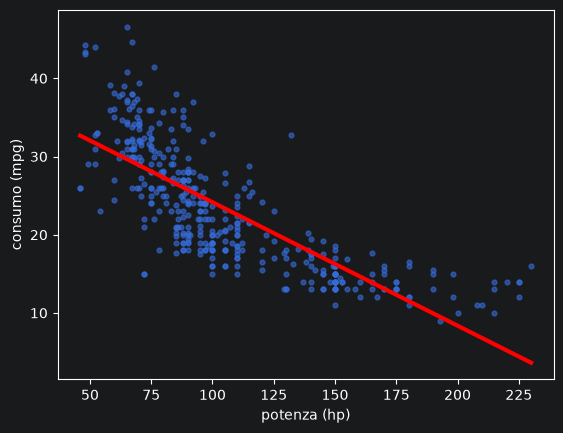

In [5]:
ordine = hp.argsort()
plt.scatter(hp, y, s=12, alpha=.6)
plt.plot(hp[ordine], (alpha * x + beta).detach()[ordine], color="red", lw=3)
plt.xlabel("potenza (hp)"); plt.ylabel("consumo (mpg)");

Forse il modello lineare semplice non è adatto a descrivere la relazione tra $x$ e $y$, quindi potrebbe non fornirci previsioni adeguate su dati di automobili che non conosciamo.

Aggiungiamo una feature, per vedere se otteniamo una **rappresentazione migliore dei dati**, ovvero una che spieghi meglio la relazione tra potenza e consumo in questo dataset.

Come nuova feature, aggiungiamo il quadrato di `hp`, `hp`$^2$, e cerchiamo tramite ottimizzazione del MSE con discesa del gradiente i parametri di:

$\hat{y} = \alpha_1 x + \alpha_2 x^2 + \beta$

dove $x=$`hp` $x^2=$`hp`$^2$ $y=$`mpg`

Mettendo $x$ e $x^2$ come colonne di una matrice $X = [x, x^2]$, e coerentemente i coefficienti angolari $\alpha = [\alpha_1, \alpha_2]$ recuperiamo la notazione di prima, ma con dimensioni diverse.


In [6]:
X = torch.stack([x, x**2], dim=1) # due feature per ogni auto
Alpha = torch.zeros(2, requires_grad=True)
beta = torch.zeros(1, requires_grad=True)
lr = 0.1
n_epoche = 300
opt = torch.optim.SGD([Alpha, beta], lr=lr)
for epoca in range(n_epoche):
    y_pred = X @ Alpha + beta
    loss = ((y_pred - y)**2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()

Adesso non abbiamo più una funzione che varia linearmente con `hp`: cosa possiamo osservare?

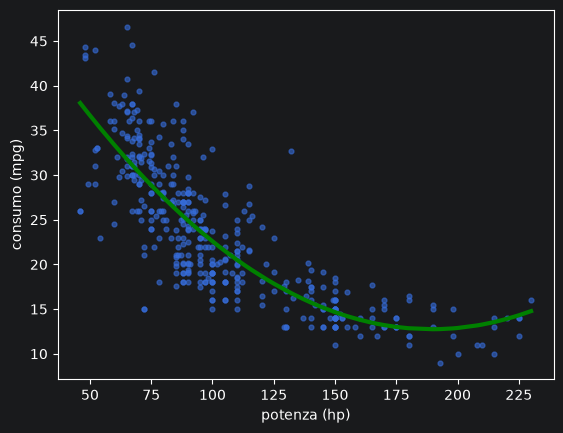

In [7]:
ordine = hp.argsort()
plt.scatter(hp, y, s=12, alpha=.6)
plt.plot(hp[ordine], (X @ Alpha + beta).detach()[ordine], color="green", lw=3)
plt.xlabel("potenza (hp)");
plt.ylabel("consumo (mpg)");
plt.show()

Adesso abbiamo provato a indovinare, aggiungendo a mano una feature, quale fosse la rappresentazione migliore dei dati per il nostro problema di capire cosa lega la potenza al consumo:

**A partire da un dataset e da una funzione di costo / perdita da ottimzzare, le reti neurali imparano automaticamente la rappresentazione migliore dei dati per minimizzarla.**

------

Fin qui abbiamo sempre riscritto il ciclo di training a mano. Mettiamolo in una funzione **riutilizzabile**, che prende in input le feature `X` e il target `y` e restituisce i parametri imparati e la storia della loss:

In [8]:
def train_regressione_lineare(X, y, lr=0.1, epoche=300):
    """Regressione lineare: ritorna pesi, bias e la storia della loss."""
    Alpha = torch.zeros(X.shape[1], requires_grad=True)
    beta = torch.zeros(1, requires_grad=True)
    opt = torch.optim.SGD([Alpha, beta], lr=lr)
    storia = []
    for _ in range(epoche):
        loss = ((X @ Alpha + beta - y)**2).mean()      # MSE
        opt.zero_grad(); loss.backward(); opt.step()
        storia.append(loss.item())
    return Alpha.detach(), beta.detach(), storia

Scriviamo anche una funzione per il plot, così da non ripetere ogni volta `scatter` + `plot`:

In [21]:
def plot_regressione_lineare(x, y_true, y_pred, xlabel="x", ylabel="y", title=""):
    """Punti (x, y_true) + retta/curva predetta y_pred, ordinando per x."""
    ordine = x.argsort()
    plt.scatter(x, y_true, s=12, alpha=.5)
    plt.plot(x[ordine], y_pred.detach()[ordine], color="red", lw=3)
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.show()

Proviamo ora a vedere l'effetto della **learning rate** sulla discesa del gradiente: alleniamo lo stesso modello con diversi valori di `lr` e confrontiamo come scende la loss durante le epoche. Cosa succede con una `lr` troppo piccola? E troppo grande?

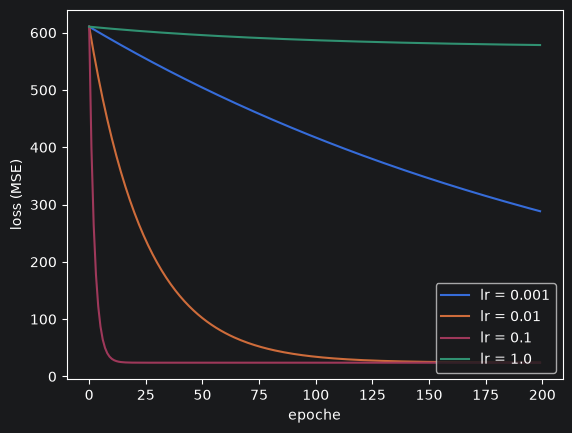

In [18]:
hp_norm = (hp - hp.mean()) / hp.std()
X = hp_norm.unsqueeze(1)  # solo hp (poi provate: X = torch.stack([hp_n, hp_n**2], dim=1))
for lr in [0.001, 0.01, 0.1, 1.0]:
    _, _, storia = train_regressione_lineare(X, y, lr=lr, epoche=200)
    plt.plot(storia, label=f"lr = {lr}")
plt.xlabel("epoche")
plt.ylabel("loss (MSE)")
plt.legend(loc="lower right")
plt.show()
plt.show()

Invece di cambiare `lr` ed `epoche` a mano e rilanciare la cella, costruiamo un'interfaccia interattiva con `ipywidgets`: degli slider ci permettono di vedere subito l'effetto dei parametri sul training.

In [22]:
from ipywidgets import interact, FloatLogSlider, IntSlider

def visualizza_regressione_lineare(lr=0.1, epoche=300, usa_hp2=False):
    X = torch.stack([hp_norm, hp_norm**2], dim=1) if usa_hp2 else hp_norm.unsqueeze(1)
    Alpha, beta, storia = train_regressione_lineare(X, y, lr=lr, epoche=epoche)
    plot_regressione_lineare(hp, y, X @ Alpha + beta, xlabel="potenza (hp)", ylabel="mpg",
             title=f"lr={lr:.3f}, epoche={epoche}, loss finale={storia[-1]:.2f}")

interact(visualizza_regressione_lineare,
         lr=FloatLogSlider(value=0.1, base=10, min=-3, max=0.3, step=0.1),
         epoche=IntSlider(value=300, min=10, max=1000, step=10));

interactive(children=(FloatLogSlider(value=0.1, description='lr', max=0.3, min=-3.0), IntSlider(value=300, des…

Tocca a voi: provate a ripetere la regressione lineare usando un'altra colonna del dataset come feature `x` al posto di `hp` (per esempio il peso `weight` dell'auto) e analizzate il risultato:

In [ ]:
# proviamo con altre colonne come x di mpg: mpg, cylinders, displacement, horsepower, weight, acceleration, model_year
# esempio: predire il consumo (mpg) dal peso (weight) dell'auto invece che dalla potenza
peso = torch.tensor(dfm["weight"].to_numpy(), dtype=torch.float32)
peso_norm = (peso - peso.mean()) / peso.std()
# TODO:
# train del modello
# plot del risultato

### Train-test split

Finora abbiamo allenato e giudicato il modello sugli stessi dati. Ma quello che conta davvero è come va su dati nuovi, mai visti (la sua _generalizzazione_).

Per questo si divide il dataset in due: una parte per allenare (train) e una tenuta da parte per valutare (test, che simula dati _nuovi_ di cui nei casi reali non abbiamo le etichette).

In [23]:
# divisione train / test “a mano”
torch.manual_seed(0)
X = torch.stack([hp_norm, hp_norm**2], dim=1)
idx = torch.randperm(len(y)) # mescolo gli indici
perc_train = int(0.75 * len(y))   # 75% train, 25% test
train_data_idx, test_data_idx = idx[:perc_train], idx[perc_train:]
X_train, y_train = X[train_data_idx], y[train_data_idx]
X_test, y_test = X[test_data_idx], y[test_data_idx]

In [24]:
Alpha, beta, storia = train_regressione_lineare(X_train, y_train, lr=0.1, epoche=300)   # alleniamo SOLO sul train

loss_train = ((X_train @ Alpha + beta - y_train) ** 2).mean()
loss_test  = ((X_test @ Alpha + beta - y_test) ** 2).mean()
print(f"loss train: {loss_train:.2f}    loss test: {loss_test:.2f}")

loss train: 19.64    loss test: 17.05


## E se ho un problema di classificazione? Regressione Logistica!

A dispetto del nome, è il gemello della regressione lineare per la classificazione: stesso loop, cambia l'ultimo passo:

![simgoid](images/sigmoid.png)

In [25]:
dfp = pd.read_csv("data/penguins.csv").dropna()
dfp.info()

<class 'pandas.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    str    
 1   island             333 non-null    str    
 2   beak_length_mm     333 non-null    float64
 3   beak_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 20.8 KB


Il nostro obiettivo è distinguere i pinguini di specie `Gentoo` dal resto, utilizzando come features la lunghezza delle pinne `flipper_length_mm` e la lunghezza del becco `beak_length_mm`.

In [26]:
feat = dfp[["beak_length_mm", "flipper_length_mm"]].to_numpy()
feat = (feat - feat.mean(0)) / feat.std(0) # standardizziamo le features (v. sopra perchè)
X = torch.tensor(feat, dtype=torch.float32)               # (N, 2)
y = torch.tensor((dfp["species"] == "Gentoo").to_numpy(), dtype=torch.float32)  # 1 = Gentoo, 0 = altri

In [27]:
# stessi elementi (coefficiente, intercetta e ottimizzatore) usati nella regressione lineare
Alpha = torch.zeros(2, requires_grad=True)
beta = torch.zeros(1, requires_grad=True)
opt = torch.optim.SGD([Alpha, beta], lr=0.1)

Nella classificazione, prima di calcolare l'errore e ottimizzare la perdita con discesa del gradiente, si assegna ogni punto ad una classe (una specie nel nostro caso).

Questo implica che anche la funzione di perdita non potrà essere lo scarto quadratico medio (che funziona solo per la regressione) ma sarà la **Binary Cross Entropy Loss**, che come suggerisce il nome è indicata per la classificazione binaria.

In [34]:
n_epoche = 300
for epoca in range(n_epoche):
    z = X @ Alpha + beta  # combinazione lineare (come la regressione)
    p = torch.sigmoid(z) # la sigmoide schiaccia z tra 0 e 1: una probabilità
    loss = torch.nn.functional.binary_cross_entropy(p, y)  # cross-entropy binaria
    # gli "obbligatori" nell'ottimizzazione con discesa del gradiente
    opt.zero_grad()
    loss.backward()
    opt.step()

In [35]:
# accuratezza: quante previsioni sono corrette (soglia a 0.5)
with torch.no_grad():
    pred = (torch.sigmoid(X @ Alpha + beta) > 0.5).float()
    acc = (pred == y).float().mean()
print(f"Accuratezza: {acc.item():.1%}")

Accuratezza: 97.6%


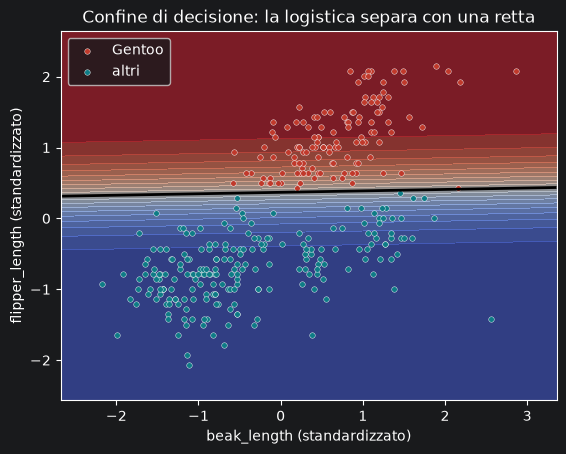

In [38]:
# griglia sul piano delle due feature (standardizzate)
x0 = X[:, 0]; x1 = X[:, 1]
gx = torch.linspace(x0.min() - 0.5, x0.max() + 0.5, 200)
gy = torch.linspace(x1.min() - 0.5, x1.max() + 0.5, 200)
xx, yy = torch.meshgrid(gx, gy, indexing="xy")
with torch.no_grad():
    griglia = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=1)
    P = torch.sigmoid(griglia @ Alpha + beta).reshape(xx.shape)

plt.contourf(xx.numpy(), yy.numpy(), P.numpy(), levels=20, cmap="coolwarm", alpha=.6)
plt.contour(xx.numpy(), yy.numpy(), P.numpy(), levels=[0.5], colors="black", linewidths=2)   # il confine (p = 0.5)
plt.scatter(x0[pred == 1], x1[pred == 1], s=16, c="#C0392B", edgecolor="white", lw=.3, label="Gentoo")
plt.scatter(x0[pred == 0], x1[pred == 0], s=16, c="#0E7C86", edgecolor="white", lw=.3, label="altri")
plt.xlabel("beak_length (standardizzato)"); plt.ylabel("flipper_length (standardizzato)")
plt.legend(); plt.title("Confine di decisione: la logistica separa con una retta"); plt.show()

A volte però è impossibile classificare accuratamente dei punti con un classficatore lineare come la regressione logistica:

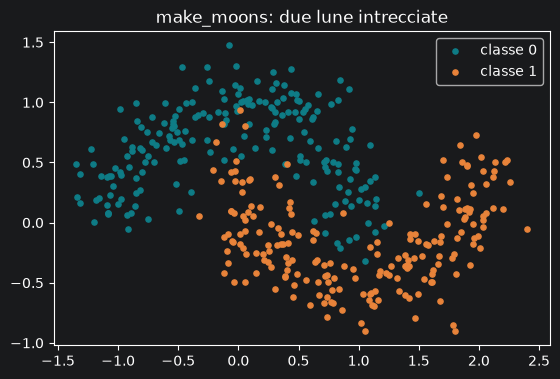

In [39]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
Xm = torch.tensor(Xm, dtype=torch.float32)
ym = torch.tensor(ym, dtype=torch.long)

# visualizziamo le due “lune”: nessuna retta riesce a separarle
plt.scatter(Xm[ym == 0, 0], Xm[ym == 0, 1], s=14, c="#0E7C86", label="classe 0")
plt.scatter(Xm[ym == 1, 0], Xm[ym == 1, 1], s=14, c="#E8833A", label="classe 1")
plt.legend(); plt.gca().set_aspect("equal")
plt.title("make_moons: due lune intrecciate"); plt.show()